<a href="https://colab.research.google.com/github/lizagabriela80-afk/Data-analyse/blob/main/Cartographie_de_processus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercice 5 : Cartographie de processus — Support informatique (AS-IS → TO-BE)


**Voici le livrable complet** :


- description du processus,
-  le code XML .drawio  
- le script Python pour exporter les PNG,
- la page d'explication et le bonus SQL.




# Partie 1 — Processus AS-IS


***Contexte***


Entreprise de ~300 salariés. Un salarié qui rencontre un problème informatique (accès, matériel, logiciel) doit passer par le service support (3 techniciens + 1 responsable).

### Acteurs du processus

| Acteur | Rôle |
|---|---|
| **Demandeur** (salarié) | Signale l'incident |
| **Manager** | Valide la demande si matériel > 500 € |
| **Support N1** (technicien) | Qualifie, résout les cas simples |
| **Support N2** (technicien expert) | Résout les cas complexes |
| **Responsable support** | Arbitre les escalades, commande le matériel |

### Étapes du processus AS-IS

| # | Étape | Acteur | Délai estimé |
|---|---|---|---|
| 1 | Découverte du problème | Demandeur | — |
| 2 | Envoi d'un email à `support@entreprise.fr` (ou appel téléphonique) | Demandeur | 5 min |
| 3 | Lecture de la boîte mail partagée (1× par jour, le matin) | Support N1 | **jusqu'à 24 h d'attente** |
| 4 | Création manuelle d'un ticket dans l'outil | Support N1 | 10 min |
| 5 | Qualification : incident connu ? | Support N1 | 15 min |
| 6a | **Si oui** : résolution et réponse par email | Support N1 | 1–4 h |
| 6b | **Si non** : escalade par email à N2 | Support N1 | 5 min |
| 7 | Prise en charge par N2 | Support N2 | **24–48 h d'attente** |
| 8 | Résolution ou demande de devis matériel | Support N2 | 2–8 h |
| 9a | **Si matériel > 500 €** : validation manager par email | Manager | **24–72 h d'attente** |
| 9b | **Sinon** : commande directement | Responsable support | 1 h |
| 10 | Commande fournisseur | Responsable support | 2–5 jours |
| 11 | Réception et installation | Support N2 | 2 h |
| 12 | Clôture du ticket + email au demandeur | Support N1 | 10 min |

**Délai total moyen constaté** : **3 à 7 jours ouvrés** pour un incident standard, jusqu'à **2 semaines** si matériel > 500 €.

### Les 3 problèmes identifiés

| # | Problème | Symptôme observable | Cause racine |
|---|---|---|---|
| **P1** | **Point d'entrée non structuré** : email + téléphone + Slack | Tickets perdus, doublons, demandeur qui relance | Pas de guichet unique ; pas de numéro de ticket communiqué |
| **P2** | **Attentes redondantes** : lecture boîte mail 1×/jour, puis prise en charge N2 24–48 h, puis validation manager 24–72 h | Délai perçu très long, frustration | Files d'attente séquentielles sans parallélisation ni alerte SLA |
| **P3** | **Relances manuelles** : le demandeur doit relancer par email pour connaître l'avancement | ~40 % des tickets font l'objet d'au moins une relance | Aucune notification automatique ; pas de statut visible |

In [1]:
import pandas as pd

In [2]:
etapes = pd.DataFrame([
    [1,  "Découverte du problème",                              "Demandeur",           "—"],
    [2,  "Envoi d'un email à support@entreprise.fr (ou appel)", "Demandeur",           "5 min"],
    [3,  "Lecture de la boîte mail partagée (1×/jour, matin)",  "Support N1",          "jusqu'à 24 h d'attente"],
    [4,  "Création manuelle d'un ticket dans l'outil",          "Support N1",          "10 min"],
    [5,  "Qualification : incident connu ?",                    "Support N1",          "15 min"],
    ["6a","Si oui : résolution et réponse par email",           "Support N1",          "1–4 h"],
    ["6b","Si non : escalade par email à N2",                   "Support N1",          "5 min"],
    [7,  "Prise en charge par N2",                              "Support N2",          "24–48 h d'attente"],
    [8,  "Résolution ou demande de devis matériel",             "Support N2",          "2–8 h"],
    ["9a","Si matériel > 500 € : validation manager par email", "Manager",             "24–72 h d'attente"],
    ["9b","Sinon : commande directement",                       "Responsable support", "1 h"],
    [10, "Commande fournisseur",                                "Responsable support", "2–5 jours"],
    [11, "Réception et installation",                           "Support N2",          "2 h"],
    [12, "Clôture du ticket + email au demandeur",              "Support N1",          "10 min"],
], columns=["#", "Étape", "Acteur", "Délai estimé"])

etapes

,#,Étape,Acteur,Délai estimé
0,1,Découverte du problème,Demandeur,—
1,2,Envoi d'un email à support@entreprise.fr (ou a...,Demandeur,5 min
2,3,"Lecture de la boîte mail partagée (1×/jour, ma...",Support N1,jusqu'à 24 h d'attente
3,4,Création manuelle d'un ticket dans l'outil,Support N1,10 min
4,5,Qualification : incident connu ?,Support N1,15 min
5,6a,Si oui : résolution et réponse par email,Support N1,1–4 h
6,6b,Si non : escalade par email à N2,Support N1,5 min
7,7,Prise en charge par N2,Support N2,24–48 h d'attente
8,8,Résolution ou demande de devis matériel,Support N2,2–8 h
9,9a,Si matériel > 500 € : validation manager par e...,Manager,24–72 h d'attente


In [11]:
problemes = pd.DataFrame([
    ["P1", "Point d'entrée non structuré (email + téléphone + Slack)",
           "Tickets perdus, doublons, demandeur qui relance",
           "Pas de guichet unique ; pas de numéro de ticket communiqué"],
    ["P2", "Attentes redondantes (lecture mail 1×/j → N2 24–48 h → manager 24–72 h)",
           "Délai perçu très long, frustration",
           "Files d'attente séquentielles sans parallélisation ni alerte SLA"],
    ["P3", "Relances manuelles du demandeur",
           "~40 % des tickets font l'objet d'au moins une relance",
           "Aucune notification automatique ; pas de statut visible"],
], columns=["#", "Problème", "Symptôme observable", "Cause racine"])

problemes

,#,Problème,Symptôme observable,Cause racine
0,P1,Point d'entrée non structuré (email + téléphon...,"Tickets perdus, doublons, demandeur qui relance",Pas de guichet unique ; pas de numéro de ticke...
1,P2,Attentes redondantes (lecture mail 1×/j → N2 2...,"Délai perçu très long, frustration",Files d'attente séquentielles sans parallélisa...
2,P3,Relances manuelles du demandeur,~40 % des tickets font l'objet d'au moins une ...,Aucune notification automatique ; pas de statu...


# Partie 2 — Schéma BPMN AS-IS (fichier .drawio)


--- Schéma AS-IS ---


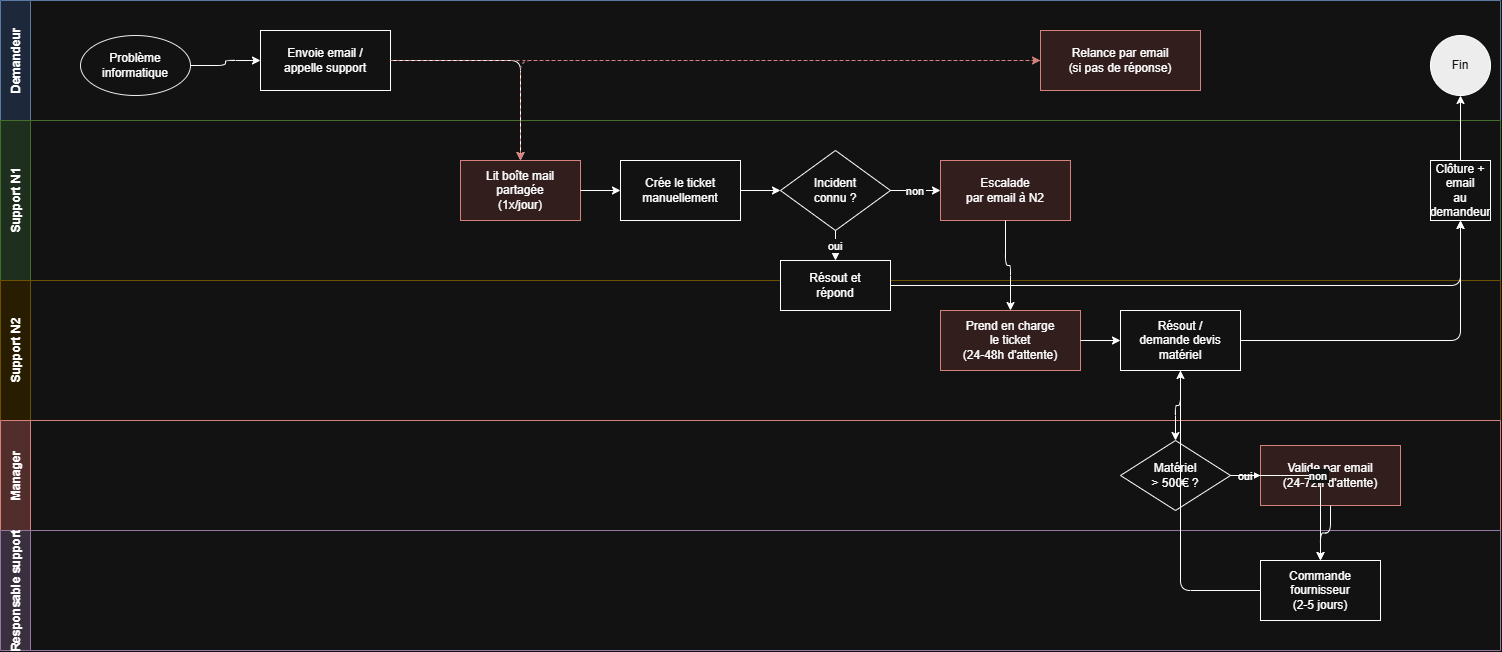

In [9]:
from IPython.display import Image, display

print("--- Schéma AS-IS ---")
try:
    display(Image(filename='/content/asis.drawio.png'))
except Exception as e:
    print("Erreur lors du chargement de l'image AS-IS :", e)

--- Schéma TO-BE ---


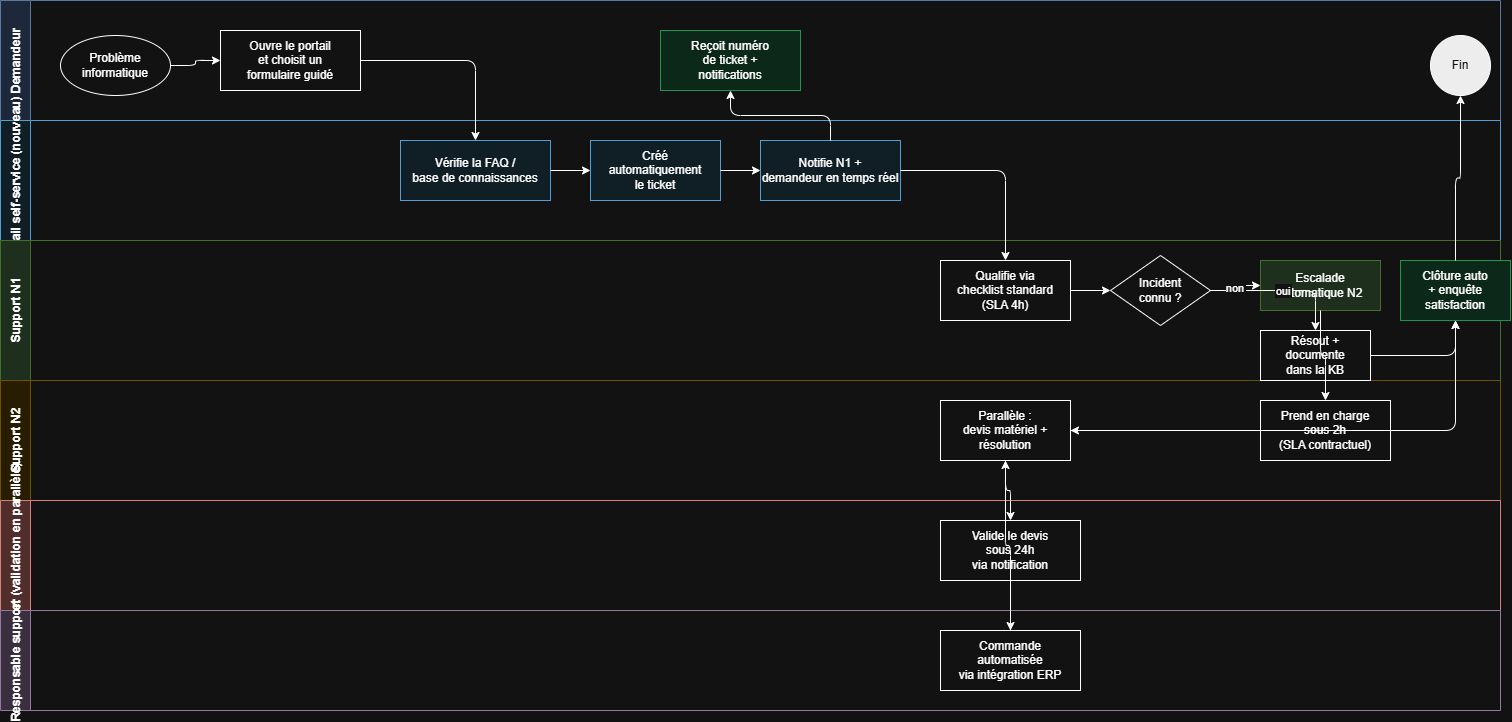

In [10]:
print("--- Schéma TO-BE ---")
try:
    display(Image(filename='/content/tobe.drawio.png'))
except Exception as e:
    print("Erreur lors du chargement de l'image TO-BE :", e)